# Block 2. Observation effort

The hotspot table only has detections: no clouds, no list of overpasses. So "no hotspot" can mean
no fire, a fire that was not seen, or no observation at all. This block builds indirect measures of
how well each satellite was watching. Plan: `docs/eda-plan.md`, block 2.
Results: `docs/findings/02-observation-effort.md`.

Inputs: the hotspot table and the quality flags of block 1. Days are `burn_date`.

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)  # duckdb -> pandas noise
pd.set_option("display.width", 200, "display.max_columns", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "NASA_Data_Sources").is_dir())
P = ROOT / "NASA_Data_Sources" / "processed"
con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
# Every hotspot with its flags: this block needs the static sources the quality filter removes.
con.execute(f"""
    CREATE TABLE a AS
    SELECT t.satellite, t.instrument, t.acq_datetime, t.burn_date, t.burn_year, t.burn_month,
           t.pass_slot::VARCHAR AS pass_slot, t.latitude, t.longitude, t.country, t.admin1,
           q.in_static_mask, q.keep
    FROM read_parquet('{P}/hotspots/*/*.parquet', hive_partitioning=true) t
    JOIN read_parquet('{P}/quality/quality_flags.parquet') q USING (satellite, acq_datetime, latitude, longitude)
""")


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


ORDER = ["Terra", "Aqua", "Suomi-NPP", "NOAA-20", "NOAA-21"]
q("SELECT count(*) AS rows, sum(in_static_mask::INT) AS static_source_rows, sum(keep::INT) AS kept FROM a")

,rows,static_source_rows,kept
0,8042380,398084.0,7000520.0


## 2.1 How many satellites were watching

Satellites with at least one detection anywhere in Chile and Argentina, per day.

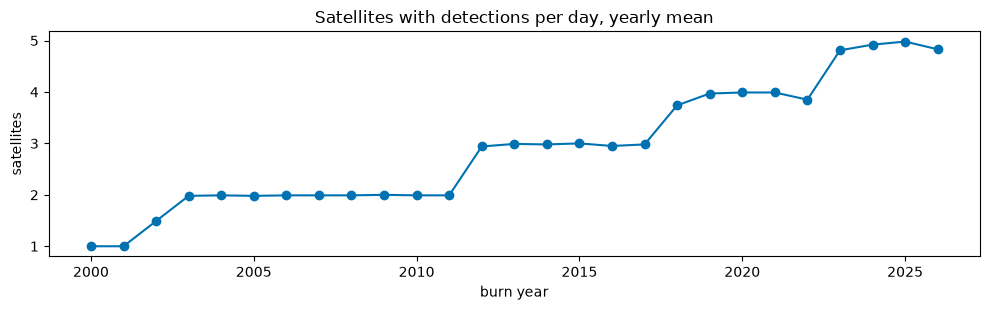

burn_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean,1.0,1.0,1.49,1.98,1.99,1.98,1.99,1.99,1.99,2.0,1.99,1.99,2.94,2.99,2.98,3.0,2.95,2.98,3.74,3.97,3.99,3.99,3.85,4.81,4.92,4.98,4.83
min,1.0,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,2.00,2.00,2.00,2.0,1.00,1.00,3.00,3.00,3.00,3.00,2.00,3.00,4.00,3.00,1.00
max,1.0,1.0,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.0,2.00,2.00,3.00,3.00,3.00,3.0,3.00,3.00,4.00,4.00,4.00,4.00,4.00,5.00,5.00,5.00,5.00


In [2]:
per_day = q("SELECT burn_date, burn_year, count(DISTINCT satellite) AS satellites FROM a GROUP BY ALL")
by_year = per_day.groupby("burn_year").satellites.agg(["mean", "min", "max"]).round(2)
ax = by_year["mean"].plot(figsize=(10, 3.2), marker="o", color="#0072B2")
ax.set(title="Satellites with detections per day, yearly mean", xlabel="burn year", ylabel="satellites")
plt.tight_layout()
plt.show()
by_year.T

Towards the pole the orbits overlap, so a place can be seen by two consecutive orbits of the same
satellite (about 100 minutes apart). Share of the cell-passes with fire (0.25° cell, satellite, day
and pass) that were detected by two or more orbits, by latitude band. An orbit starts when the gap
to the previous detection in the cell is over 50 minutes.

In [3]:
q("""
    WITH d AS (
        SELECT satellite, burn_date, pass_slot, floor(latitude * 4) AS cy, floor(longitude * 4) AS cx, acq_datetime,
               lag(acq_datetime) OVER (PARTITION BY satellite, burn_date, pass_slot, floor(latitude * 4), floor(longitude * 4)
                                       ORDER BY acq_datetime) AS previous
        FROM a WHERE keep AND burn_year BETWEEN 2019 AND 2021 AND satellite IN ('Aqua', 'Suomi-NPP')),
    passes AS (
        SELECT satellite, burn_date, pass_slot, cy, cx,
               1 + count(*) FILTER (WHERE acq_datetime - previous > INTERVAL 50 MINUTE) AS orbits
        FROM d GROUP BY ALL)
    SELECT satellite, CAST(floor(cy / 4 / 10) * 10 AS INT) AS lat_from, count(*) AS cell_passes_with_fire,
           round(100 * avg((orbits >= 2)::INT), 1) AS pct_seen_by_two_orbits
    FROM passes GROUP BY ALL ORDER BY satellite, lat_from DESC
""").pivot(index="lat_from", columns="satellite", values=["cell_passes_with_fire", "pct_seen_by_two_orbits"]).sort_index(ascending=False)

cell_passes_with_fire           pct_seen_by_two_orbits          
satellite                  Aqua Suomi-NPP                   Aqua Suomi-NPP
lat_from                                                                  
-20                        35.0     239.0                    0.0       0.0
-30                     43272.0  122776.0                    0.0       7.6
-40                     19373.0   60142.0                    0.7       9.4
-50                       885.0    2450.0                    2.8      12.7
-60                        12.0     293.0                    8.3      15.7

## 2.2 Static sources as witnesses

A gas flare or a smelter burns every night. If a satellite does not report it, the reason is the
satellite, the clouds or the sensor's sensitivity, not the absence of fire. That makes the static
sources of the block 1 mask a test of the observation itself.

Sites: 0.05° boxes inside the mask that Suomi-NPP detected on at least 1,000 nights in 2013-2025.
Nights only: a steady source against a cold background is the cleanest signal.

In [4]:
con.execute("""
    CREATE TABLE s AS
    SELECT *, CAST(floor(latitude * 20) AS INT) AS sy, CAST(floor(longitude * 20) AS INT) AS sx
    FROM a WHERE in_static_mask AND pass_slot = 'night_pass'
""")
con.execute("""
    CREATE TABLE sites AS
    SELECT sy, sx, any_value(country) AS country, mode(admin1) AS admin1, count(DISTINCT burn_date) AS nights
    FROM s WHERE satellite = 'Suomi-NPP' AND burn_year BETWEEN 2013 AND 2025
    GROUP BY 1, 2 HAVING count(DISTINCT burn_date) >= 1000
""")
con.execute("""
    ALTER TABLE sites ADD COLUMN zone VARCHAR;
    UPDATE sites SET zone = CASE
        WHEN country = 'Chile' AND (admin1 LIKE '%Arica%' OR admin1 LIKE '%Tarapac%' OR admin1 LIKE '%Antofagasta%' OR admin1 LIKE '%Atacama%')
            THEN 'Northern Chile desert'
        WHEN country = 'Chile' THEN 'Central and southern Chile'
        WHEN admin1 IN ('Neuquén', 'Río Negro', 'Mendoza', 'La Pampa') THEN 'Neuquén basin'
        WHEN admin1 IN ('Buenos Aires', 'Santa Fe', 'Entre Ríos', 'Ciudad Autónoma de Buenos Aires') THEN 'Paraná and Buenos Aires'
        ELSE 'Rest of Argentina' END
""")
con.execute("CREATE TABLE zones AS SELECT zone, count(*) AS n_sites FROM sites GROUP BY 1")
q("SELECT zone, count(*) AS sites, round(median(nights)) AS median_nights_detected, list(DISTINCT admin1) AS regions FROM sites GROUP BY 1 ORDER BY 2 DESC")

,zone,sites,median_nights_detected,regions
0,Paraná and Buenos Aires,7,2436.0,"[Buenos Aires, Santa Fe]"
1,Northern Chile desert,5,2111.0,"[Región de Antofagasta, Región de Atacama]"
2,Central and southern Chile,5,2018.0,"[Región Metropolitana de Santiago, Región del ..."
3,Neuquén basin,2,1185.0,"[Neuquén, Mendoza]"


Share of nights each satellite reports each site, 2019-2021 (the four satellites that flew
the whole period, MODIS orbits still stable). The same sources, the same nights.

In [5]:
rate = q("""
    SELECT satellite, zone, count(DISTINCT (sy, sx, burn_date)) AS site_nights_detected,
           any_value(n_sites) * 1096 AS site_nights
    FROM s JOIN sites USING (sy, sx) JOIN zones USING (zone)
    WHERE burn_year BETWEEN 2019 AND 2021 AND satellite IN ('Terra', 'Aqua', 'Suomi-NPP', 'NOAA-20')
    GROUP BY satellite, zone
""")
rate["pct_of_nights"] = (100 * rate.site_nights_detected / rate.site_nights).round(1)
by_zone = rate.pivot(index="zone", columns="satellite", values="pct_of_nights")[["Terra", "Aqua", "Suomi-NPP", "NOAA-20"]]
overall = rate.groupby("satellite")[["site_nights_detected", "site_nights"]].sum()
by_zone.loc["All sites"] = (100 * overall.site_nights_detected / overall.site_nights).round(1)
by_zone

satellite,Terra,Aqua,Suomi-NPP,NOAA-20
zone,,,,
Central and southern Chile,6.2,3.6,51.5,52.3
Neuquén basin,0.4,0.0,40.1,41.7
Northern Chile desert,4.9,2.9,50.1,51.4
Paraná and Buenos Aires,2.6,1.4,48.1,50.6
All sites,3.9,2.2,48.7,50.3


Per year: outages and the drift of the MODIS orbits show up as changes in the detection rate of
sources that did not change.

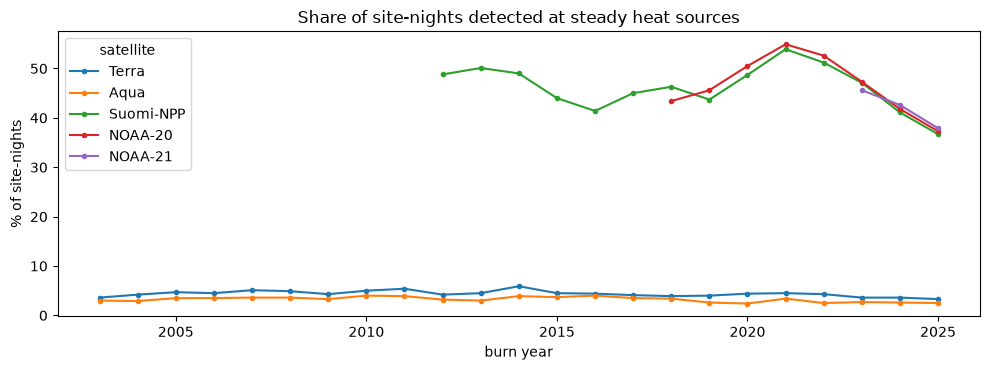

burn_year,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
satellite,,,,,,,,,,,,,,,,,,,,,,,
Terra,3.6,4.2,4.7,4.5,5.1,4.9,4.3,5.0,5.4,4.2,4.5,5.9,4.5,4.4,4.1,3.9,4.0,4.4,4.5,4.3,3.6,3.6,3.3
Aqua,3.0,2.9,3.5,3.5,3.6,3.6,3.3,4.0,3.9,3.2,3.0,3.9,3.7,4.0,3.5,3.4,2.6,2.4,3.4,2.5,2.7,2.6,2.5
Suomi-NPP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.8,50.1,49.0,44.0,41.4,45.0,46.3,43.7,48.7,53.9,51.2,47.1,41.1,36.7
NOAA-20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.4,45.6,50.5,54.9,52.6,47.3,41.8,37.3
NOAA-21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.6,42.6,37.9


In [6]:
n_sites = q("SELECT count(*) AS n FROM sites").n[0]
yearly = q(f"""
    WITH operating AS (  -- nights the satellite reported anything in the two countries
        SELECT satellite, burn_year, count(DISTINCT burn_date) AS op_nights FROM a
        WHERE pass_slot = 'night_pass' GROUP BY ALL)
    SELECT satellite, burn_year,
           100.0 * count(DISTINCT (sy, sx, burn_date)) / ({n_sites} * any_value(op_nights)) AS pct
    FROM s JOIN sites USING (sy, sx) JOIN operating USING (satellite, burn_year)
    WHERE burn_year BETWEEN 2003 AND 2025 GROUP BY satellite, burn_year
""").pivot(index="burn_year", columns="satellite", values="pct").round(1)[ORDER]
ax = yearly.plot(figsize=(10, 3.8), marker="o", ms=3)
ax.set(title="Share of site-nights detected at steady heat sources", xlabel="burn year", ylabel="% of site-nights")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "findings" / "02-witness-rate.png", dpi=130)
plt.show()
yearly.T

Per calendar month (Suomi-NPP, 2013-2025): the season of the clouds. A zone where the rate drops in
some months is a zone where fires in those months are also under-observed.

In [7]:
season = q("""
    WITH nights AS (SELECT burn_month, count(DISTINCT burn_date) AS n FROM a
                    WHERE satellite = 'Suomi-NPP' AND burn_year BETWEEN 2013 AND 2025 GROUP BY 1)
    SELECT zone, burn_month,
           100.0 * count(DISTINCT (sy, sx, burn_date)) / (any_value(n_sites) * any_value(n)) AS pct
    FROM s JOIN sites USING (sy, sx) JOIN zones USING (zone) JOIN nights USING (burn_month)
    WHERE satellite = 'Suomi-NPP' AND burn_year BETWEEN 2013 AND 2025 GROUP BY zone, burn_month
""").pivot(index="zone", columns="burn_month", values="pct").round(0)
season.assign(lowest=season.min(axis=1), highest=season.max(axis=1))

burn_month,1,2,3,4,5,6,7,8,9,10,11,12,lowest,highest
zone,,,,,,,,,,,,,,
Central and southern Chile,59.0,65.0,58.0,46.0,38.0,36.0,34.0,35.0,38.0,43.0,57.0,57.0,34.0,65.0
Neuquén basin,28.0,28.0,29.0,29.0,22.0,16.0,15.0,20.0,26.0,30.0,31.0,27.0,15.0,31.0
Northern Chile desert,56.0,60.0,59.0,53.0,47.0,42.0,43.0,48.0,45.0,48.0,51.0,52.0,42.0,60.0
Paraná and Buenos Aires,51.0,53.0,54.0,48.0,39.0,40.0,37.0,48.0,47.0,48.0,55.0,50.0,37.0,55.0


## 2.3 Where there are no witnesses

The test above only works where steady sources exist. Sites per latitude band:

In [8]:
q("""
    SELECT CAST(floor(sy / 20.0 / 5) * 5 AS INT) AS lat_band, count(*) AS witness_sites,
           list(DISTINCT admin1) AS regions FROM sites GROUP BY 1 ORDER BY 1 DESC
""")

,lat_band,witness_sites,regions
0,-25,3,[Región de Antofagasta]
1,-30,2,[Región de Atacama]
2,-35,10,"[Región Metropolitana de Santiago, Mendoza, Re..."
3,-40,4,"[Región del Bío-Bío, Neuquén, Buenos Aires]"


Days with at least one kept hotspot per region and year (Suomi-NPP, 2013-2025), for the regions with
the fewest: few detections there can be little fire or poor observation, and this table cannot tell.

In [9]:
q("""
    SELECT country, admin1, round(count(DISTINCT burn_date) / 13.0) AS days_with_hotspots_per_year,
           round(count(*) / 13.0) AS hotspots_per_year
    FROM a WHERE keep AND satellite = 'Suomi-NPP' AND burn_year BETWEEN 2013 AND 2025 AND admin1 IS NOT NULL
    GROUP BY ALL ORDER BY 3 LIMIT 8
""")

,country,admin1,days_with_hotspots_per_year,hotspots_per_year
0,Argentina,Ciudad Autónoma de Buenos Aires,3.0,3.0
1,Chile,Región de Aysén del Gral.Ibañez del Campo,18.0,175.0
2,Argentina,"Tierra del Fuego, Antártida e Islas del Atlánt...",28.0,144.0
3,Chile,Región de Arica y Parinacota,39.0,64.0
4,Chile,Región de Magallanes y Antártica Chilena,40.0,96.0
5,Chile,Región de Los Ríos,56.0,316.0
6,Chile,Región de Tarapacá,59.0,114.0
7,Chile,Región de Los Lagos,76.0,566.0
